# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Indian CS Student Survival Dataset](https://www.kaggle.com/datasets/pranavsinghdeveloper/desi-cs-student-survival?select=students.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('students.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,student_id,age,gender,home_region,home_town_type,branch,college_tier,year_of_study,residence,relationship_status,tenth_pct,twelfth_pct,entrance_percentile,attendance_pct,bunked_classes_per_month,proxy_attendance_count,study_hours_daily,studies_only_night_before_exam,all_nighters_before_exam,sleep_hours,gaming_hours_weekly,ott_hours_weekly,phone_screen_time_hrs,chai_cups_per_day,energy_drinks_per_week,maggi_per_week,delivery_orders_per_month,monthly_pocket_money_inr,wifi_speed_mbps,mess_rating,food_poisoning_incidents,sunday_biryani_attendance_pct,mess_review_text,reason_for_last_bunk,cgpa,backlogs,leetcode_solved,github_commits_last_year,projects_built,hackathons_attended,certifications_count,internships,club_memberships,linkedin_connections,communication_skill,genai_prompts_per_day,stackoverflow_copy_paste_index,uses_linux_btw,owns_mechanical_keyboard,parent_placement_queries_per_week,imposter_syndrome,stress_level,burnout_score,burnout_level,placed,placement_category,offers_received,package_lpa,archetype
0,S00001,20,Male,Central,Small town,Cyber Security,2,1,Hostel,Single,67.0,68.9,51.69,62.1,17,6,1.1,True,4,5.6,16.5,15.5,5.6,5,1,0,0,5500.0,20.9,2.0,1.0,58.0,Chai was lukewarm sadness. Wifi was down too.,"Lag spiked, mood crashed, class skipped.",NaN,1,44.0,300.0,0,1,0,0,0,26,2.0,10,7.0,True,False,1,5.0,5.0,46.7,Medium,NaN,NaN,NaN,NaN,gaming_ghost
1,S00002,20,Male,West,Tier-2 city,AI&ML,2,2,Day scholar,Situationship,75.7,76.4,78.25,80.6,7,0,1.9,True,1,6.5,5.1,3.0,4.1,0,1,0,5,7200.0,32.1,NaN,NaN,NaN,NaN,Was organising the hostel night.,7.06,1,0.0,12.0,0,2,1,0,2,298,10.0,4,5.0,True,False,1,4.0,4.0,50.3,Medium,NaN,NaN,NaN,NaN,hostel_socialite
2,S00003,20,Male,Central,Tier-2 city,ECE (but codes),1,3,Hostel,Single,74.1,71.6,73.81,66.1,15,0,2.5,True,0,8.3,4.6,6.5,7.3,4,2,5,11,8400.0,21.2,5.0,0.0,76.0,Edible. Sunday biryani saves the week.,Meeting with the sponsor. Very important. Very...,7.03,1,8.0,11.0,2,0,6,0,1,675,4.0,7,3.0,False,False,0,5.0,3.0,38.8,Low,NaN,NaN,NaN,NaN,club_netaji
3,S00004,22,Male,South,Tier-2 city,ECE (but codes),3,3,PG / Rented flat,Single,96.6,93.2,77.54,72.2,13,1,2.4,False,1,6.1,7.2,11.4,8.3,1,3,2,5,5000.0,137.9,6.0,1.0,100.0,"Not great, not terrible. Survival mode on. Tbh...",Was at the placement cell asking about companies.,8.05,0,25.0,16.0,3,1,9,0,2,65,6.0,9,3.0,False,False,1,5.0,4.0,65.7,High,NaN,NaN,NaN,NaN,certificate_collector
4,S00005,18,Female,South,Metro,CSE,3,1,Hostel,Single,84.5,90.1,78.00,87.0,7,0,5.0,False,0,10.0,0.0,0.0,1.7,0,1,3,0,8800.0,13.5,4.0,1.0,81.0,"Decent breakfast, tragic dinner. Still better ...",Skipped to finish the assignment due next month.,8.91,0,70.0,48.0,2,0,2,0,0,66,4.0,1,3.0,True,False,2,4.0,1.0,15.9,Low,NaN,NaN,NaN,NaN,library_topper


## last Five row

In [4]:
df.tail()

,student_id,age,gender,home_region,home_town_type,branch,college_tier,year_of_study,residence,relationship_status,tenth_pct,twelfth_pct,entrance_percentile,attendance_pct,bunked_classes_per_month,proxy_attendance_count,study_hours_daily,studies_only_night_before_exam,all_nighters_before_exam,sleep_hours,gaming_hours_weekly,ott_hours_weekly,phone_screen_time_hrs,chai_cups_per_day,energy_drinks_per_week,maggi_per_week,delivery_orders_per_month,monthly_pocket_money_inr,wifi_speed_mbps,mess_rating,food_poisoning_incidents,sunday_biryani_attendance_pct,mess_review_text,reason_for_last_bunk,cgpa,backlogs,leetcode_solved,github_commits_last_year,projects_built,hackathons_attended,certifications_count,internships,club_memberships,linkedin_connections,communication_skill,genai_prompts_per_day,stackoverflow_copy_paste_index,uses_linux_btw,owns_mechanical_keyboard,parent_placement_queries_per_week,imposter_syndrome,stress_level,burnout_score,burnout_level,placed,placement_category,offers_received,package_lpa,archetype
9995,S09996,22,Female,East,Tier-2 city,Cyber Security,2,4,Day scholar,Single,78.7,79.4,67.09,55.9,16,1,2.2,True,3,6.1,11.4,14.5,5.6,2,1,1,9,4700.0,11.0,NaN,NaN,NaN,NaN,Roommate's birthday celebration went till 5 AM.,6.48,1,2.0,6.0,3,2,3,0,0,201,8.0,9,5.0,True,False,4,5.0,7.0,67.7,High,Yes,Service Mass Recruiter,2.0,4.25,hostel_socialite
9996,S09997,20,Female,North,Tier-2 city,Data Science,3,2,Day scholar,Committed,78.1,68.3,54.14,43.6,26,3,0.0,True,5,5.8,24.5,8.9,7.0,6,0,1,7,3300.0,88.1,NaN,NaN,NaN,NaN,Fever. 103. Only during the 9 AM lecture.,5.73,2,0.0,16.0,1,1,0,0,3,129,6.0,10,7.0,False,False,2,6.0,7.0,59.6,Medium,NaN,NaN,NaN,NaN,backbench_legend
9997,S09998,22,Male,East,Tier-2 city,Cyber Security,2,4,Day scholar,Committed,80.0,75.5,58.01,30.0,33,3,1.3,True,4,4.9,21.3,10.3,8.3,2,2,2,4,8800.0,52.5,NaN,NaN,NaN,NaN,Fever. 103. Only during the 9 AM lecture.,NaN,10,44.0,30.0,3,1,2,1,0,178,6.0,13,9.0,False,False,2,7.0,8.0,78.1,High,No,Not Placed,0.0,NaN,backbench_legend
9998,S09999,20,Male,East,Metro,CSE,2,2,Day scholar,Single,86.2,76.8,97.93,73.8,16,0,3.4,True,0,7.3,1.8,5.1,5.5,2,1,1,7,7000.0,57.6,NaN,NaN,NaN,NaN,Thoda headache tha. Thoda zyada nahi tha.,7.69,0,11.0,3055.0,3,2,4,0,2,338,5.0,9,2.0,False,False,2,5.0,4.0,46.0,Medium,NaN,NaN,NaN,NaN,leetcode_grinder
9999,S10000,18,Male,East,Village,Data Science,2,1,PG / Rented flat,Committed,78.6,74.7,65.23,63.3,14,0,0.6,False,2,7.2,6.3,9.6,7.5,2,1,4,8,3500.0,127.9,8.0,0.0,95.0,"Fresh, hot and not a single hair. Miracle. Sen...","Mess ka khana was suspicious, stomach said no.",6.71,1,24.0,20.0,0,1,0,0,1,236,8.0,4,5.0,False,True,0,4.0,6.0,47.4,Medium,NaN,NaN,NaN,NaN,hostel_socialite


## Shape of our dataset

In [5]:
df.shape

(10000, 59)

## List out all columns

In [6]:
df.columns

Index(['student_id', 'age', 'gender', 'home_region', 'home_town_type',
       'branch', 'college_tier', 'year_of_study', 'residence',
       'relationship_status', 'tenth_pct', 'twelfth_pct',
       'entrance_percentile', 'attendance_pct', 'bunked_classes_per_month',
       'proxy_attendance_count', 'study_hours_daily',
       'studies_only_night_before_exam', 'all_nighters_before_exam',
       'sleep_hours', 'gaming_hours_weekly', 'ott_hours_weekly',
       'phone_screen_time_hrs', 'chai_cups_per_day', 'energy_drinks_per_week',
       'maggi_per_week', 'delivery_orders_per_month',
       'monthly_pocket_money_inr', 'wifi_speed_mbps', 'mess_rating',
       'food_poisoning_incidents', 'sunday_biryani_attendance_pct',
       'mess_review_text', 'reason_for_last_bunk', 'cgpa', 'backlogs',
       'leetcode_solved', 'github_commits_last_year', 'projects_built',
       'hackathons_attended', 'certifications_count', 'internships',
       'club_memberships', 'linkedin_connections', 'communicat

## Datatype of each columns

In [7]:
df.dtypes

student_id                            object
age                                    int64
gender                                object
home_region                           object
home_town_type                        object
branch                                object
college_tier                           int64
year_of_study                          int64
residence                             object
relationship_status                   object
tenth_pct                            float64
twelfth_pct                          float64
entrance_percentile                  float64
attendance_pct                       float64
bunked_classes_per_month               int64
proxy_attendance_count                 int64
study_hours_daily                    float64
studies_only_night_before_exam          bool
all_nighters_before_exam               int64
sleep_hours                          float64
gaming_hours_weekly                  float64
ott_hours_weekly                     float64
phone_scre

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 59 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   student_id                         10000 non-null  object 
 1   age                                10000 non-null  int64  
 2   gender                             10000 non-null  object 
 3   home_region                        10000 non-null  object 
 4   home_town_type                     10000 non-null  object 
 5   branch                             10000 non-null  object 
 6   college_tier                       10000 non-null  int64  
 7   year_of_study                      10000 non-null  int64  
 8   residence                          10000 non-null  object 
 9   relationship_status                10000 non-null  object 
 10  tenth_pct                          9827 non-null   float64
 11  twelfth_pct                        9797 non-null   floa

## Check Null Value

In [9]:
df.isnull().sum()

student_id                              0
age                                     0
gender                                  0
home_region                             0
home_town_type                          0
branch                                  0
college_tier                            0
year_of_study                           0
residence                               0
relationship_status                     0
tenth_pct                             173
twelfth_pct                           203
entrance_percentile                     0
attendance_pct                          0
bunked_classes_per_month                0
proxy_attendance_count                  0
study_hours_daily                     292
studies_only_night_before_exam          0
all_nighters_before_exam                0
sleep_hours                           315
gaming_hours_weekly                     0
ott_hours_weekly                        0
phone_screen_time_hrs                   0
chai_cups_per_day                 

## Drop columns with more than 40% missing values

In [10]:
threshold = 0.40
cols_to_drop = df.columns[df.isnull().mean() > threshold]

print("\nColumns dropped:")
print(cols_to_drop.tolist())
df = df.drop(columns=cols_to_drop)


Columns dropped:
['placed', 'placement_category', 'offers_received', 'package_lpa']


## Separate numerical and categorical columns

In [11]:
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

## Fill numerical columns using median

In [12]:
for col in numerical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

## Fill categorical columns using mode

In [13]:
for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

## Check Dupicate Value

In [14]:
df.duplicated().sum()

np.int64(0)

## Summary

In [15]:
df.describe()

,age,college_tier,year_of_study,tenth_pct,twelfth_pct,entrance_percentile,attendance_pct,bunked_classes_per_month,proxy_attendance_count,study_hours_daily,all_nighters_before_exam,sleep_hours,gaming_hours_weekly,ott_hours_weekly,phone_screen_time_hrs,chai_cups_per_day,energy_drinks_per_week,maggi_per_week,delivery_orders_per_month,monthly_pocket_money_inr,wifi_speed_mbps,mess_rating,food_poisoning_incidents,sunday_biryani_attendance_pct,cgpa,backlogs,leetcode_solved,github_commits_last_year,projects_built,hackathons_attended,certifications_count,internships,club_memberships,linkedin_connections,communication_skill,genai_prompts_per_day,stackoverflow_copy_paste_index,parent_placement_queries_per_week,imposter_syndrome,stress_level,burnout_score
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.00000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,20.288800,2.352000,2.443800,81.105110,79.532140,72.598217,69.53137,13.721800,1.667200,2.018460,1.964400,6.53394,9.231390,6.761740,5.565750,2.384400,1.858800,2.910900,6.035300,6051.010000,28.82290,4.911300,0.865100,68.96520,7.158884,0.770100,37.949800,108.096500,1.102800,1.01730,2.272100,0.22690,1.03990,220.685000,5.653400,7.873500,4.939200,2.488100,5.002400,4.667400,53.019720
std,1.448311,0.726601,1.113358,6.431551,8.272966,14.291762,13.13444,6.200181,2.076843,1.359901,1.630889,1.05535,7.113241,3.810741,1.582568,1.683544,1.561123,2.019943,4.368771,2450.214141,26.53482,1.636918,0.794207,15.21739,0.829155,1.321144,94.862819,420.571727,1.273183,1.17972,2.523311,0.58228,1.29718,263.938352,1.875319,4.008354,1.737989,2.172034,1.607312,1.706478,14.041436
min,18.000000,1.000000,1.000000,57.300000,50.000000,29.390000,30.00000,0.000000,0.000000,0.000000,0.000000,3.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1400.000000,0.50000,1.000000,0.000000,10.00000,4.550000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.00000,5.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,4.200000
25%,20.000000,2.000000,1.000000,76.800000,74.000000,62.515000,60.30000,9.000000,0.000000,1.000000,0.000000,5.80000,2.875000,4.000000,4.500000,1.000000,1.000000,1.000000,3.000000,4400.000000,12.20000,4.000000,0.000000,61.00000,6.580000,0.000000,2.000000,11.000000,0.000000,0.00000,0.000000,0.00000,0.00000,73.000000,4.000000,5.000000,4.000000,1.000000,4.000000,4.000000,43.600000
50%,20.000000,3.000000,2.000000,81.000000,79.600000,72.285000,69.40000,14.000000,1.000000,1.900000,2.000000,6.50000,8.800000,6.700000,5.600000,2.000000,2.000000,3.000000,5.000000,5600.000000,21.40000,5.000000,1.000000,69.00000,7.140000,0.000000,11.000000,29.000000,1.000000,1.00000,1.000000,0.00000,1.00000,141.000000,6.000000,7.000000,5.000000,2.000000,5.000000,5.000000,52.800000
75%,22.000000,3.000000,3.000000,85.500000,85.100000,82.820000,78.80000,18.000000,2.000000,3.000000,3.000000,7.20000,14.500000,9.400000,6.700000,3.000000,3.000000,4.000000,9.000000,7200.000000,36.30000,6.000000,1.000000,76.00000,7.710000,1.000000,35.000000,72.000000,2.000000,2.00000,3.000000,0.00000,2.00000,273.000000,7.000000,10.000000,6.000000,4.000000,6.000000,6.000000,62.300000
max,24.000000,3.000000,4.000000,99.600000,99.500000,99.990000,100.00000,33.000000,16.000000,7.300000,6.000000,10.00000,36.000000,20.600000,11.200000,12.000000,14.000000,12.000000,26.000000,25500.000000,300.00000,10.000000,6.000000,100.00000,10.000000,15.000000,1800.000000,5938.000000,10.000000,8.00000,21.000000,5.00000,9.00000,6516.000000,10.000000,27.000000,10.000000,14.000000,10.000000,10.000000,100.000000


# EDA

In [16]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

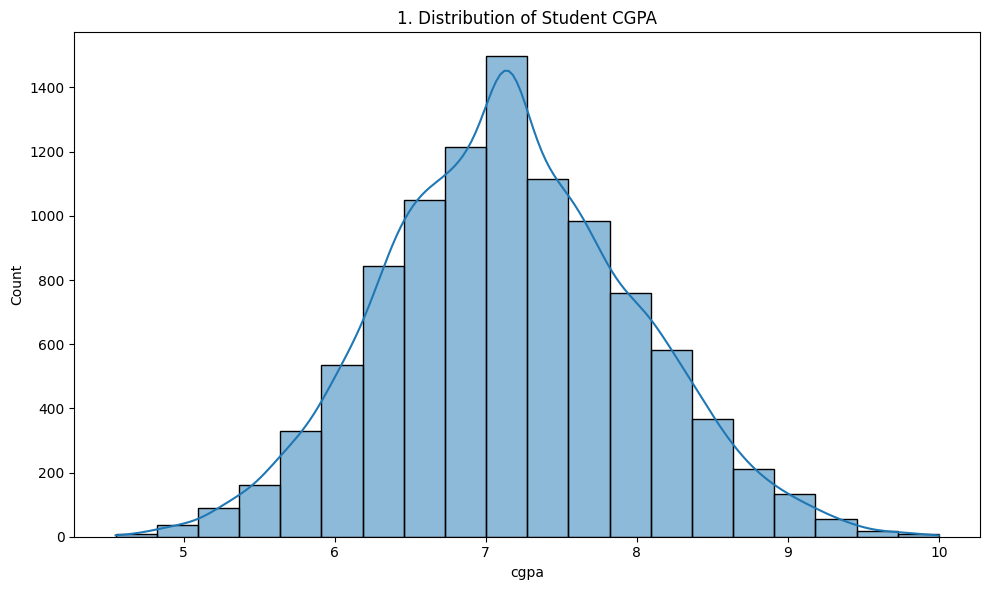

In [17]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='cgpa', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Student CGPA')
show_fig()
plot_no += 1

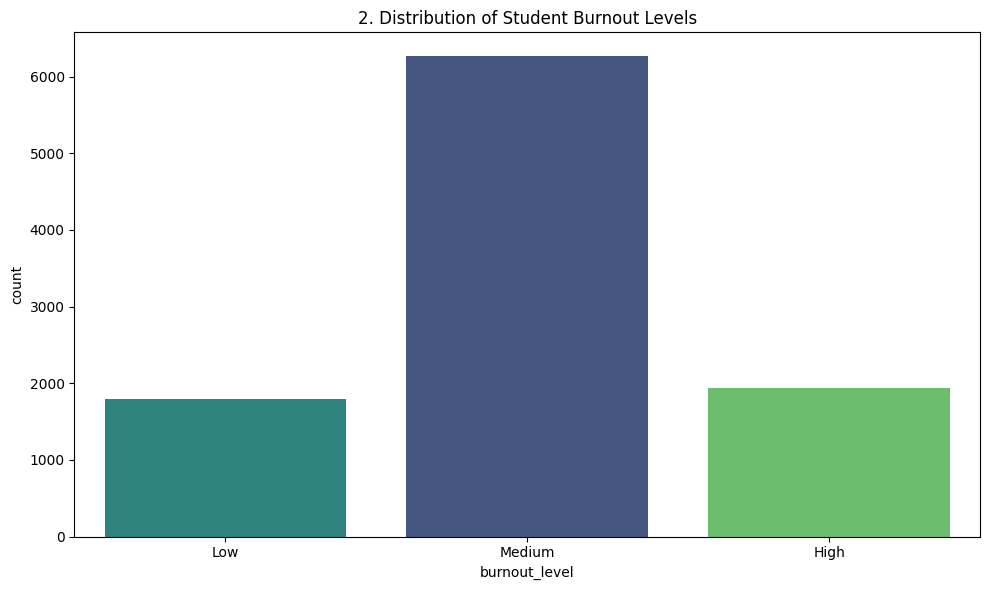

In [18]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='burnout_level', order=['Low', 'Medium', 'High'], hue='burnout_level', palette='viridis', legend=False)
plt.title(f'{plot_no}. Distribution of Student Burnout Levels')
show_fig()
plot_no += 1

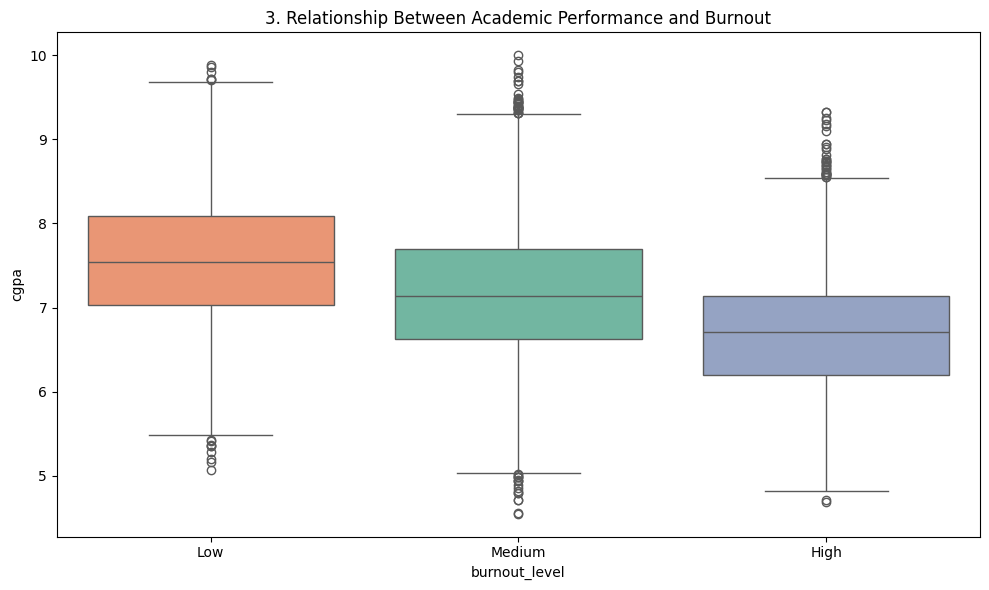

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='burnout_level', y='cgpa', order=['Low', 'Medium', 'High'], hue='burnout_level', palette='Set2', legend=False)
plt.title(f'{plot_no}. Relationship Between Academic Performance and Burnout')
show_fig()
plot_no += 1

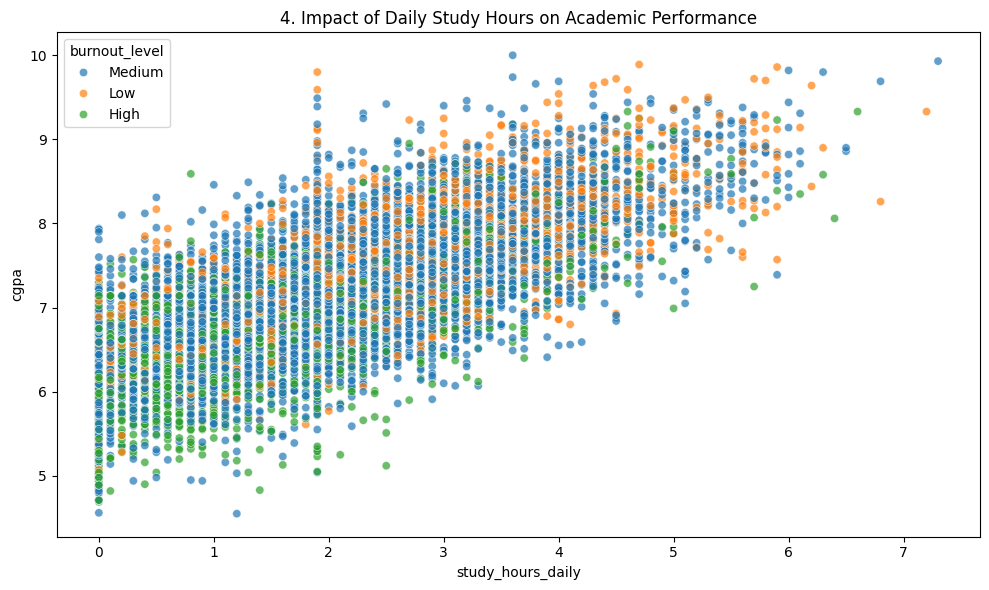

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='study_hours_daily', y='cgpa', hue='burnout_level', alpha=0.7)
plt.title(f'{plot_no}. Impact of Daily Study Hours on Academic Performance')
show_fig()
plot_no += 1

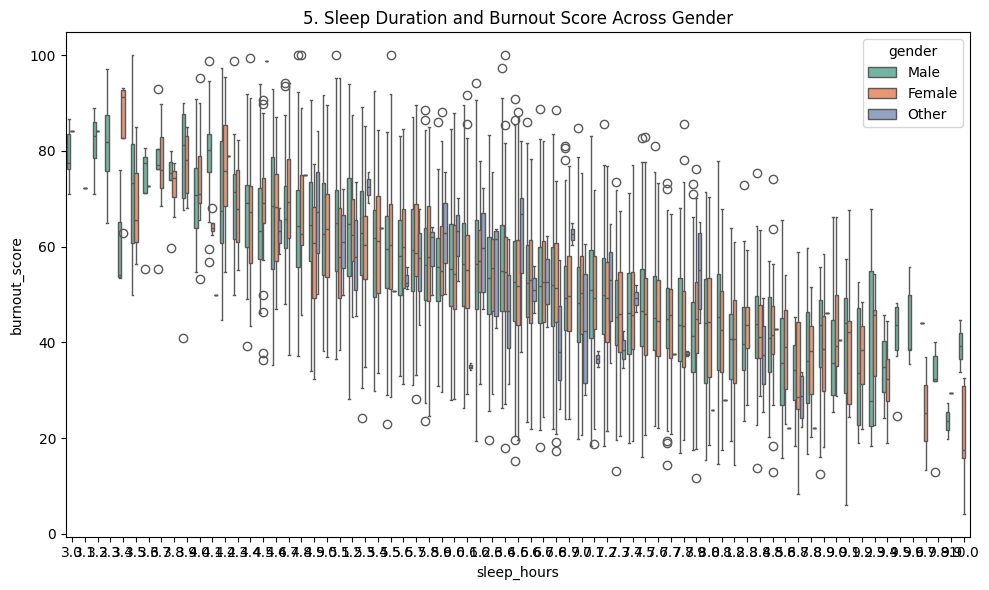

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='sleep_hours', y='burnout_score', hue='gender', palette='Set2')
plt.title(f'{plot_no}. Sleep Duration and Burnout Score Across Gender')
show_fig()
plot_no += 1

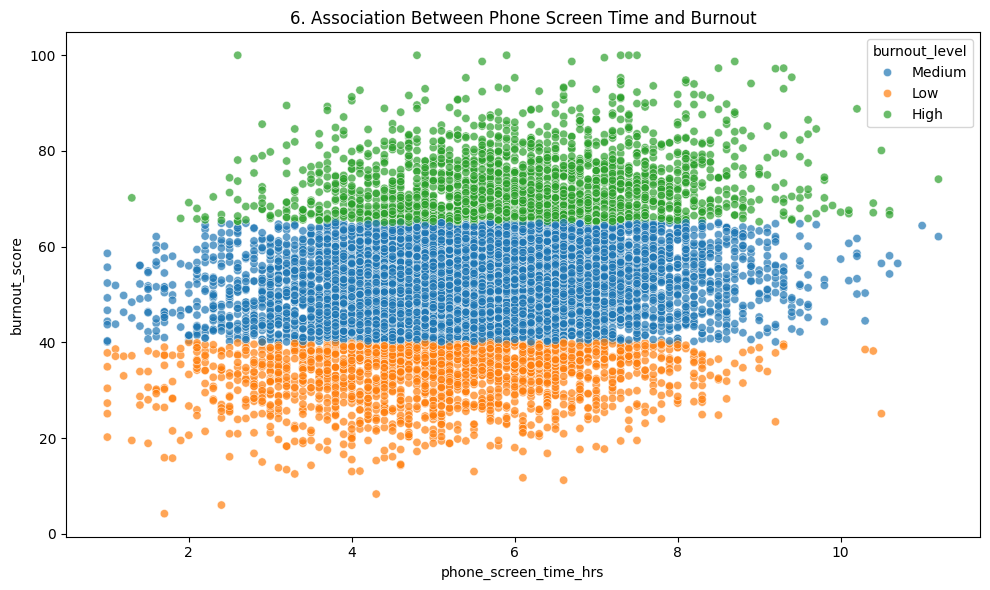

In [22]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='phone_screen_time_hrs', y='burnout_score', hue='burnout_level', alpha=0.7)
plt.title(f'{plot_no}. Association Between Phone Screen Time and Burnout')
show_fig()
plot_no += 1

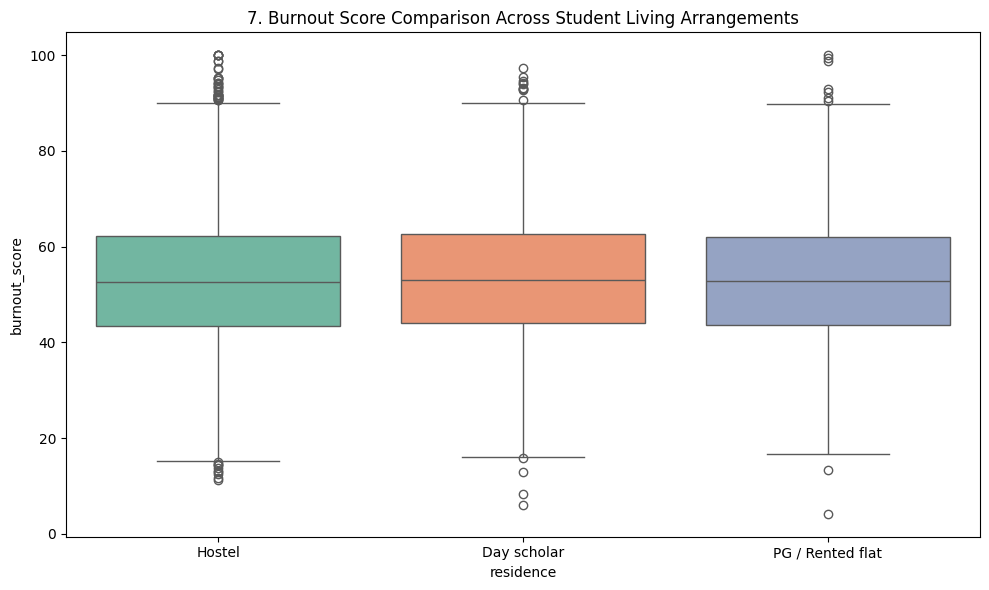

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='residence', y='burnout_score', hue='residence', palette='Set2', legend=False)
plt.title(f'{plot_no}. Burnout Score Comparison Across Student Living Arrangements')
show_fig()
plot_no += 1

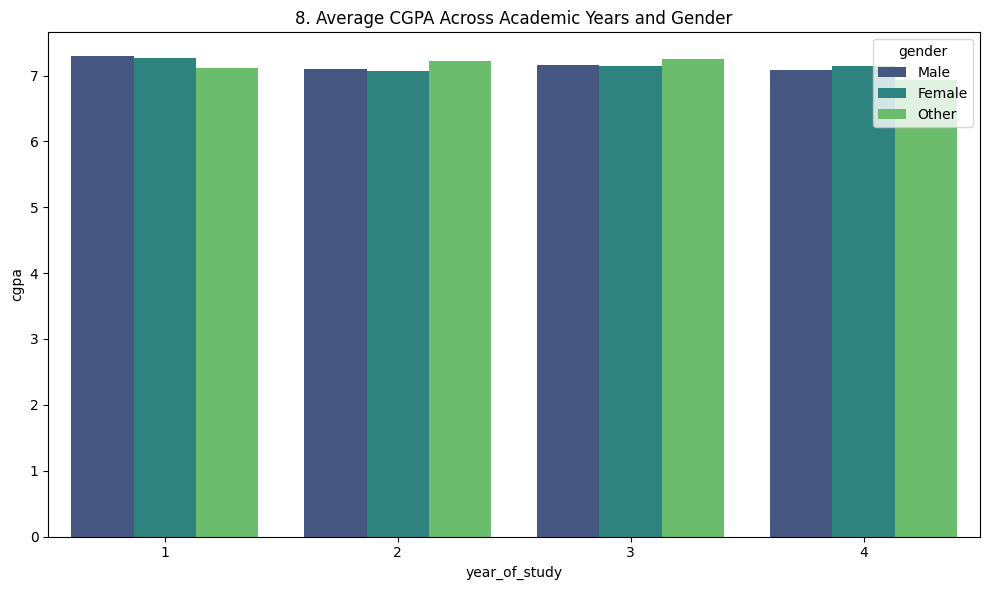

In [24]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='year_of_study', y='cgpa', hue='gender', errorbar=None, palette='viridis')
plt.title(f'{plot_no}. Average CGPA Across Academic Years and Gender')
show_fig()
plot_no += 1

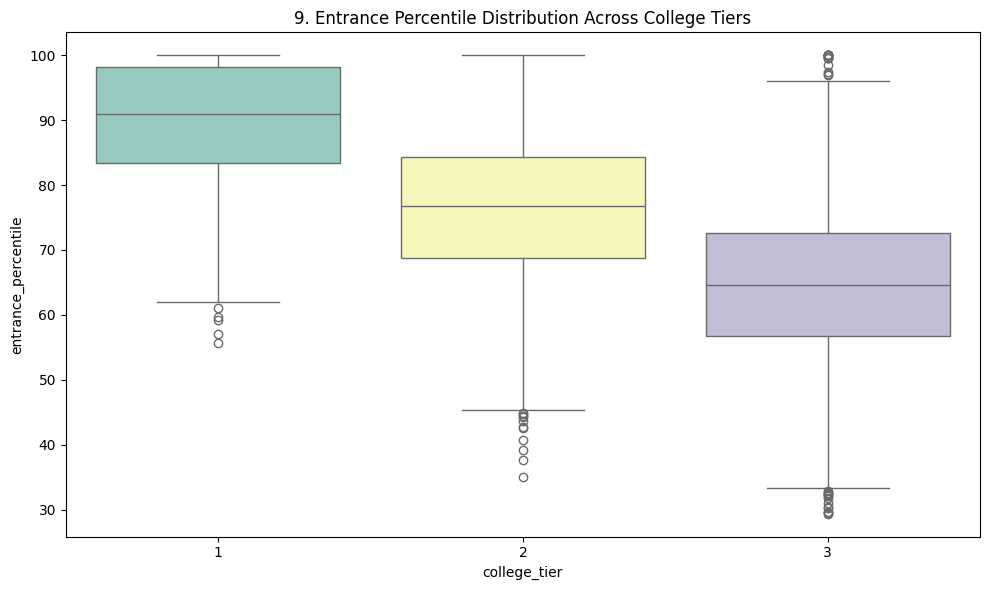

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='college_tier', y='entrance_percentile', hue='college_tier', palette='Set3', legend=False)
plt.title(f'{plot_no}. Entrance Percentile Distribution Across College Tiers')
show_fig()
plot_no += 1

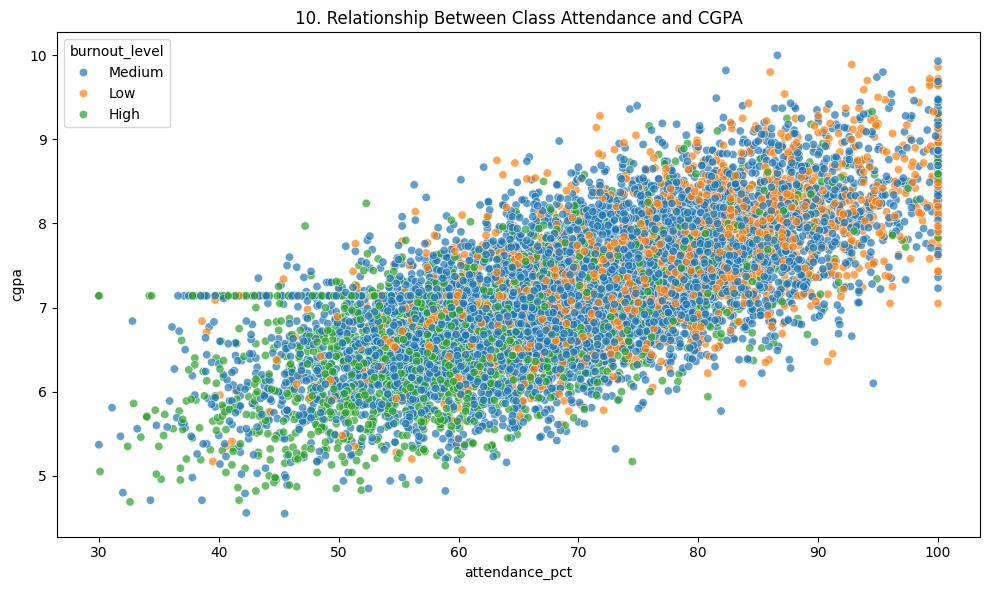

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='attendance_pct', y='cgpa', hue='burnout_level', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Class Attendance and CGPA')
show_fig()
plot_no += 1

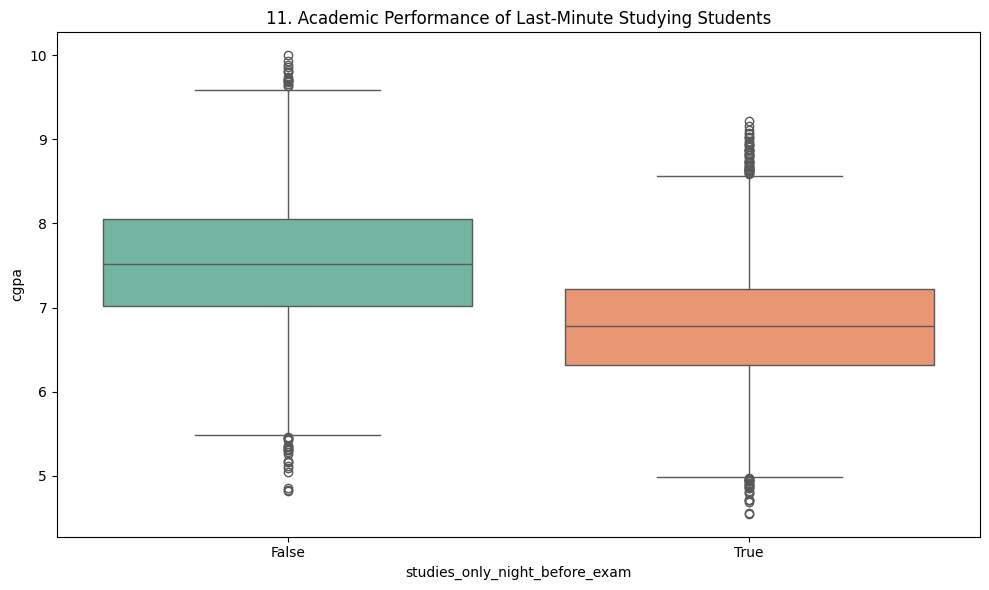

In [27]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='studies_only_night_before_exam', y='cgpa', hue='studies_only_night_before_exam', palette='Set2', legend=False)
plt.title(f'{plot_no}. Academic Performance of Last-Minute Studying Students')
show_fig()
plot_no += 1

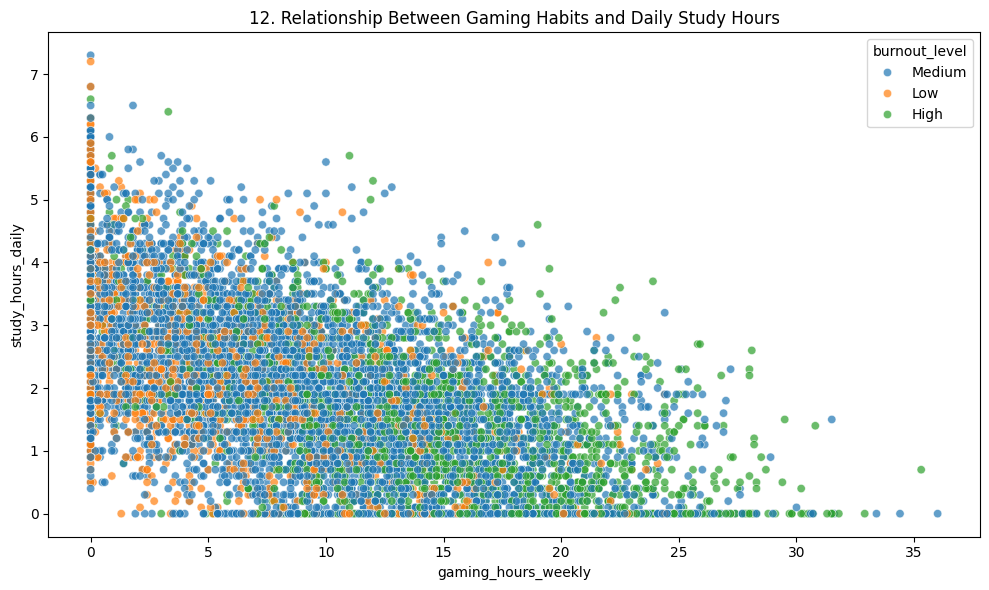

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='gaming_hours_weekly', y='study_hours_daily', hue='burnout_level', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Gaming Habits and Daily Study Hours')
show_fig()
plot_no += 1

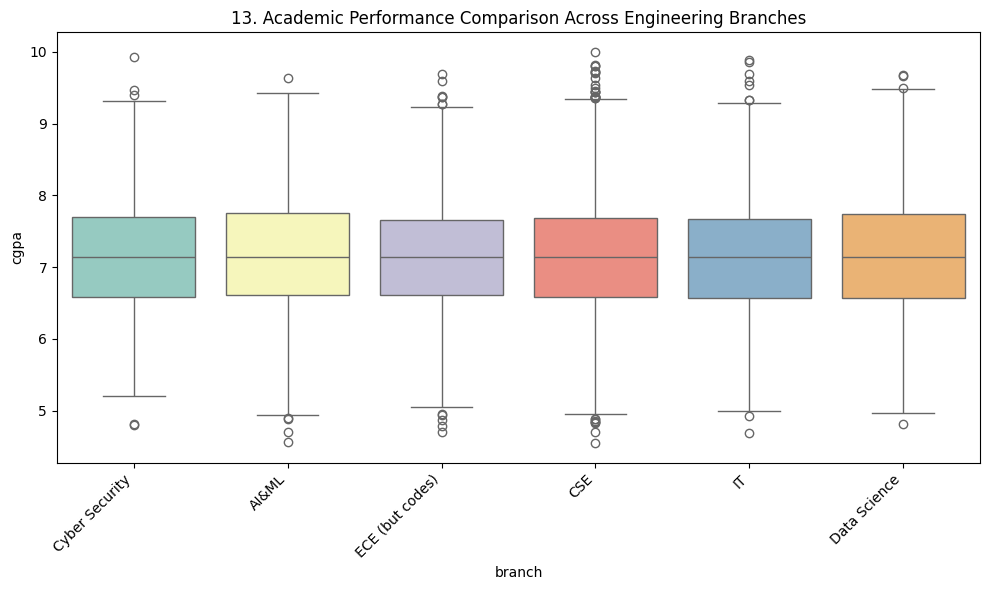

In [29]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='branch', y='cgpa', hue='branch', palette='Set3', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Academic Performance Comparison Across Engineering Branches')
show_fig()
plot_no += 1

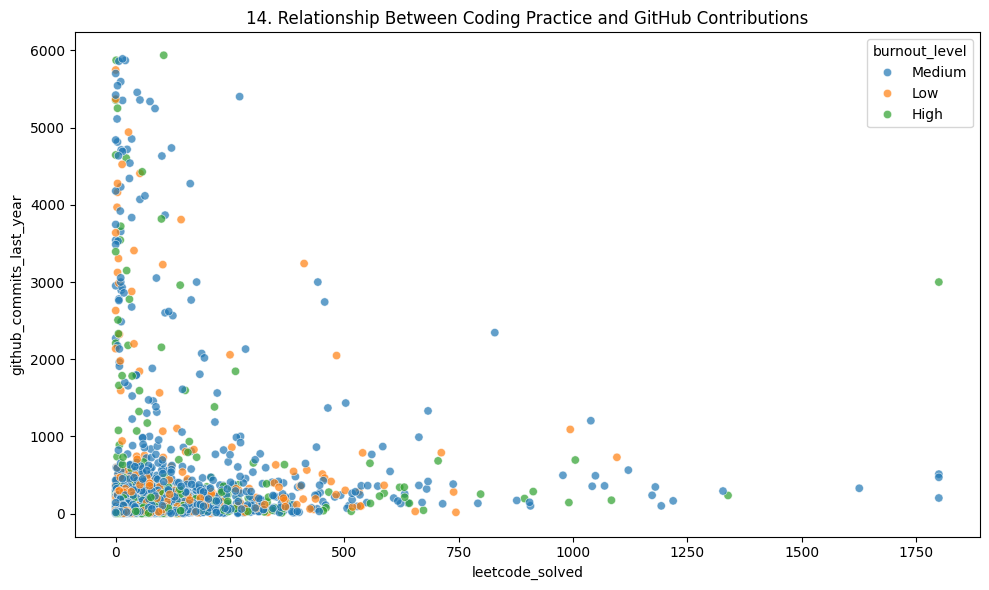

In [30]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='leetcode_solved', y='github_commits_last_year', hue='burnout_level', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Coding Practice and GitHub Contributions')
show_fig()
plot_no += 1

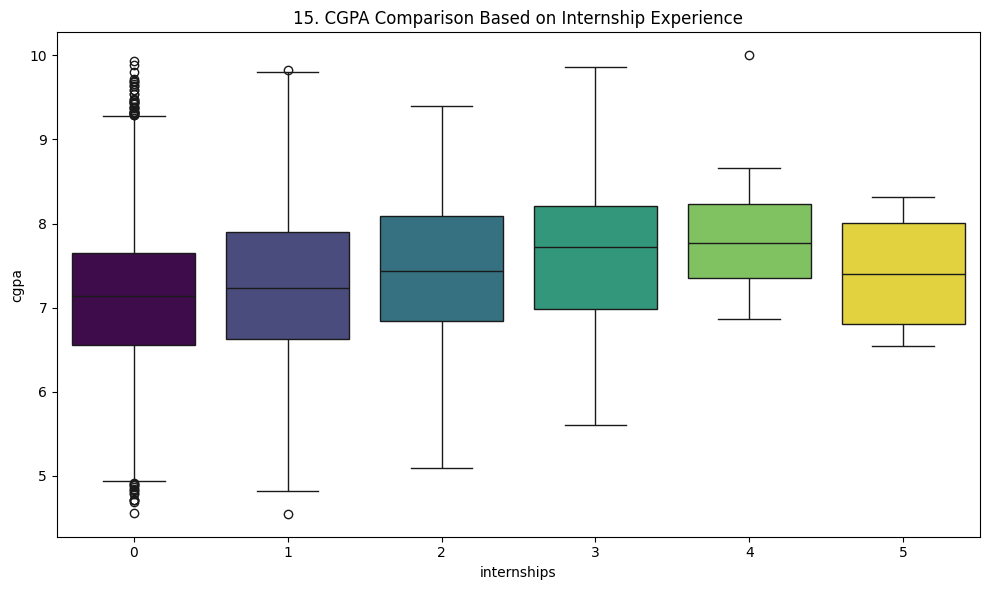

In [31]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='internships', y='cgpa', hue='internships', palette='viridis', legend=False)
plt.title(f'{plot_no}. CGPA Comparison Based on Internship Experience')
show_fig()
plot_no += 1

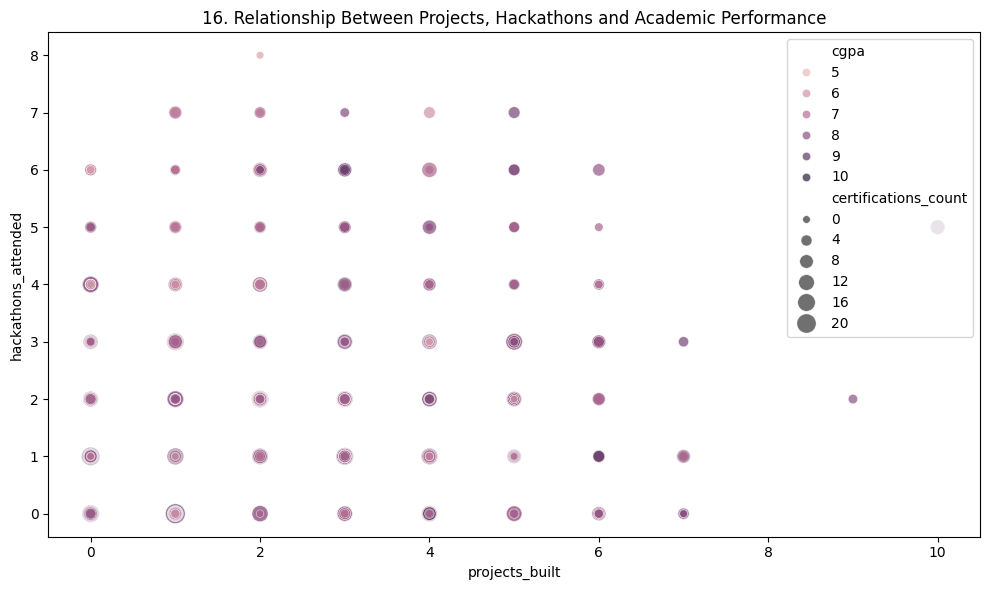

In [32]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='projects_built', y='hackathons_attended', size='certifications_count', hue='cgpa', alpha=0.7, sizes=(30, 200))
plt.title(f'{plot_no}. Relationship Between Projects, Hackathons and Academic Performance')
show_fig()
plot_no += 1

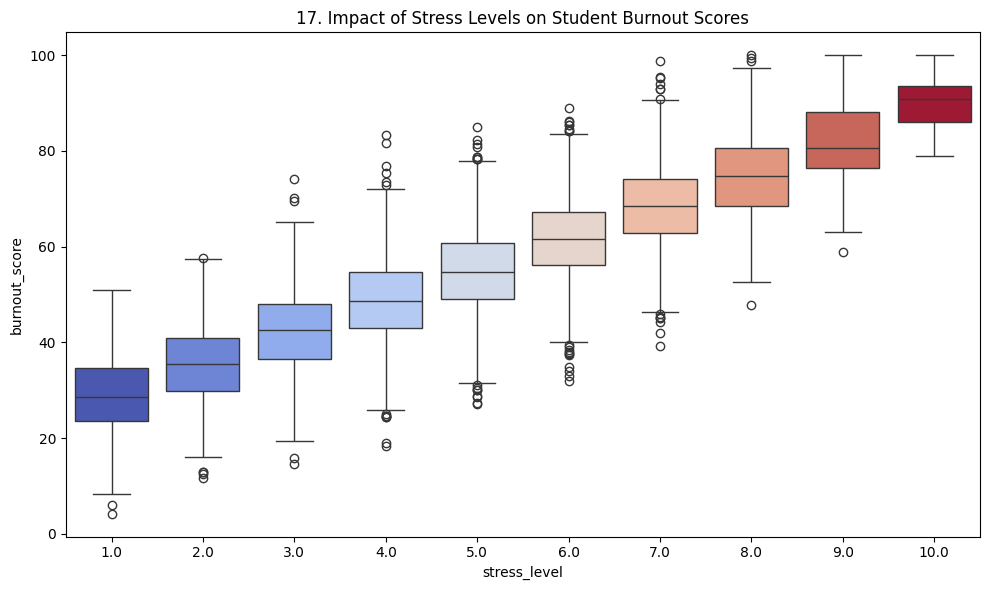

In [33]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='stress_level', y='burnout_score', hue='stress_level', palette='coolwarm', legend=False)
plt.title(f'{plot_no}. Impact of Stress Levels on Student Burnout Scores')
show_fig()
plot_no += 1

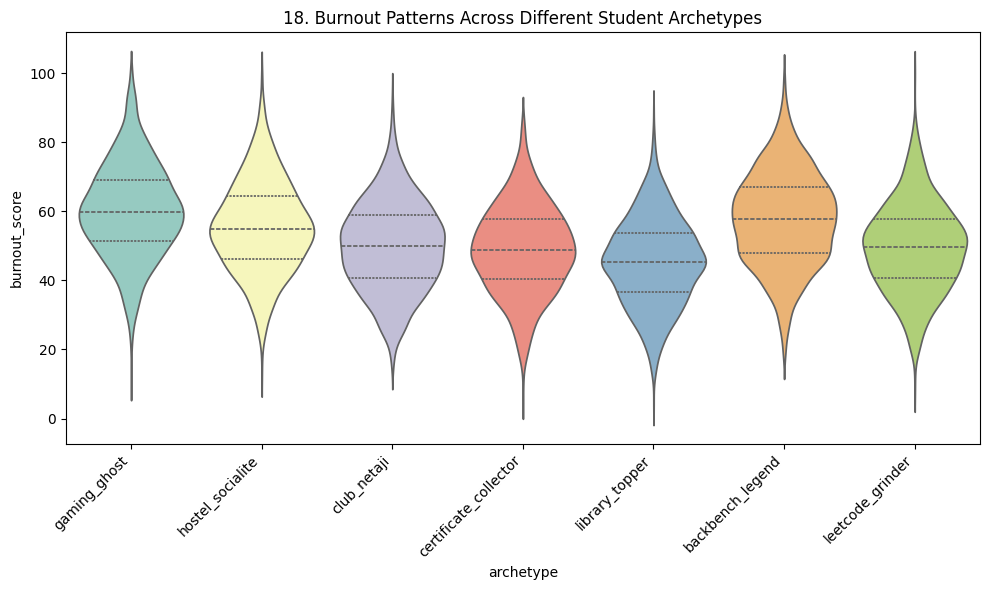

In [34]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='archetype', y='burnout_score', hue='archetype', palette='Set3', legend=False, inner='quartile')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Burnout Patterns Across Different Student Archetypes')
show_fig()
plot_no += 1

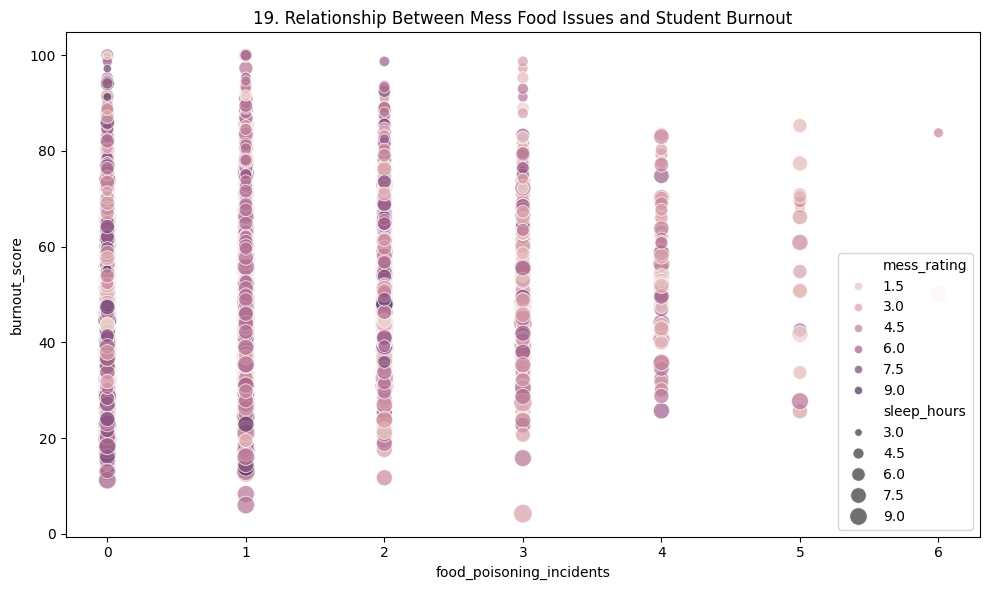

In [35]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='food_poisoning_incidents', y='burnout_score', hue='mess_rating', size='sleep_hours', alpha=0.7, sizes=(30, 180))
plt.title(f'{plot_no}. Relationship Between Mess Food Issues and Student Burnout')
show_fig()
plot_no += 1

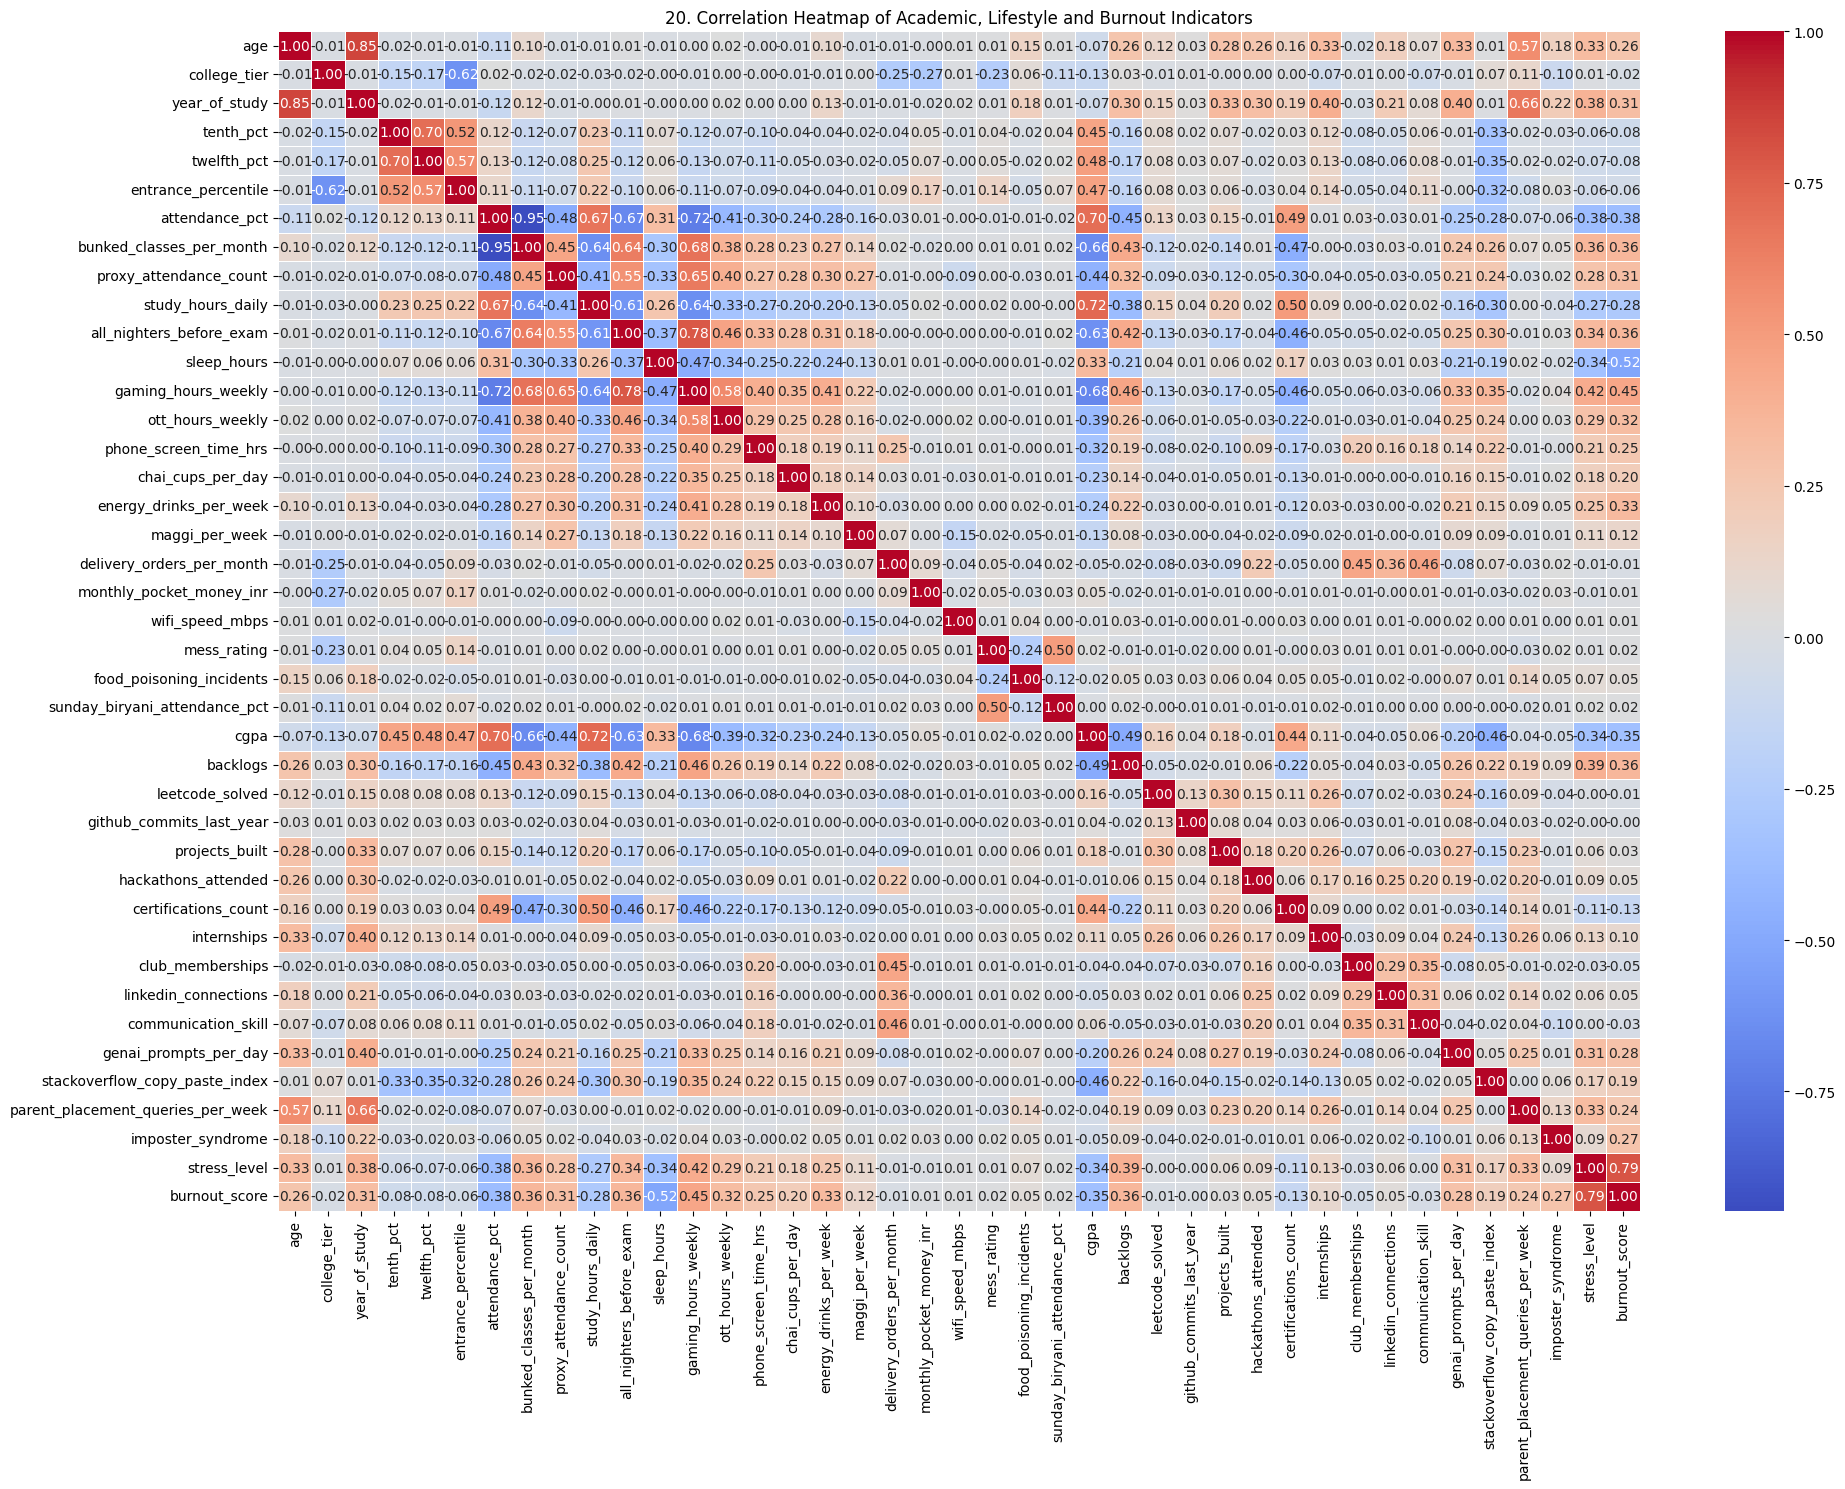

In [36]:
fig = plt.figure(figsize=(20, 15))
corr = df.select_dtypes(include='number').drop(columns=['student_id'], errors='ignore').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Academic, Lifestyle and Burnout Indicators')
show_fig()
plot_no += 1

# Model Training

## Prepare the dataset

In [37]:
data = df.drop(columns=['student_id', 'mess_review_text', 'reason_for_last_bunk'], errors='ignore').copy()
data = data.dropna(subset=['cgpa'])

X = data.drop(columns=['cgpa'])
y = data['cgpa']

X = X.dropna(axis=1, how='all')

## Identify numerical and categorical features

In [38]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

## Create preprocessing pipelines

In [39]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

## Combine preprocessing steps

In [40]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

## Split training and testing data

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

## Create the regression model

In [42]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

## Train the model

In [43]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Make predictions

In [44]:
y_pred = model.predict(X_test)

## Evaluate model performance

In [45]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Model: HistGradientBoostingRegressor")
print(f"R2 Score: {r2:.4f} ({r2 * 100:.2f}%)")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples: {len(X_test)}")

Model: HistGradientBoostingRegressor
R2 Score: 0.8110 (81.10%)
Mean Absolute Error: 0.2827
Training Samples: 8000
Testing Samples: 2000


## Plot actual vs predicted values

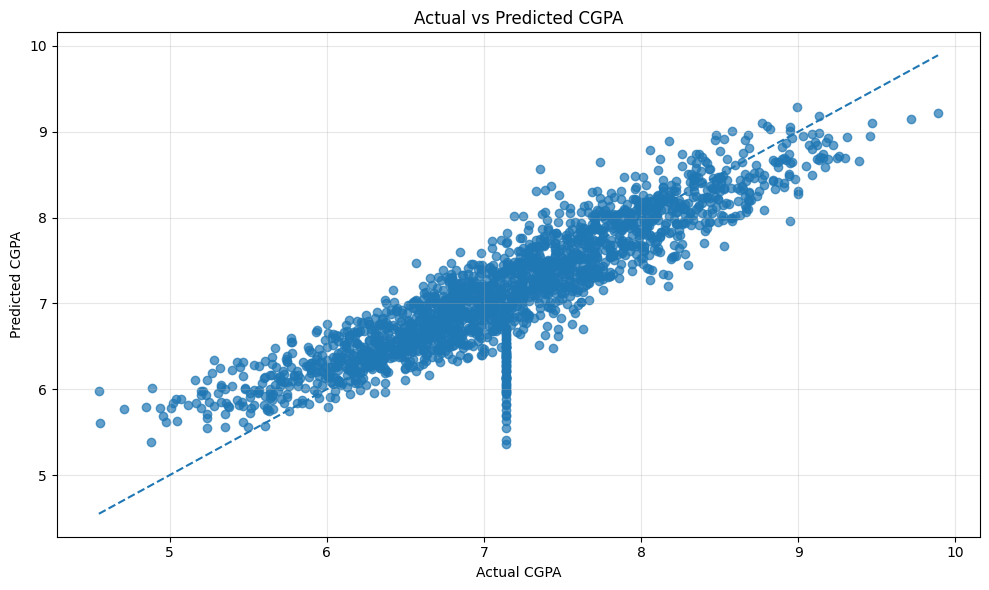

In [46]:
fig = plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
plt.xlabel('Actual CGPA')
plt.ylabel('Predicted CGPA')
plt.title('Actual vs Predicted CGPA')
plt.grid(alpha=0.3)
show_fig()
plot_no += 1